In [1]:
import pandas as pd
import numpy as np 
import cv2 
from skimage.io import imread
from os import listdir
from os.path import isfile,join
from skimage import io as sk_io
import matplotlib.pyplot as plt
from skimage.transform import resize
from skimage.feature import hog
from skimage.feature import local_binary_pattern
from skimage.color import rgb2gray

/opt/anaconda3/lib/python3.13/site-packages/pandas/core/computation/expressions.py:22: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


In [2]:
# Get the Paths For The Datasets
training_spoof_path = './Training Biometrika Spoof/Training Biometrika Spoof/spoof'
testing_spoof_path = './Testing Biometrika Spoof/Testing Biometrika Spoof/spoof'
training_live_path = './Training Biometrika Live/live'
testing_live_path = './Testing Biometrika Live/live'


In [3]:
training_spoof = [f for f in listdir(training_spoof_path) if isfile(join(training_spoof_path,f))]
testing_spoof = [f for f in listdir(testing_spoof_path) if isfile(join(testing_spoof_path,f))]
training_live = [f for f in listdir(training_live_path) if isfile(join(training_live_path,f))]
testing_live = [f for f in listdir(testing_live_path) if isfile(join(testing_live_path,f))]

print(len(training_spoof))
print(len(testing_spoof))
print(len(training_live))
print(len(testing_live))

207
200
200
200


In [4]:
training_spoof_image, label1 =[],[]
for i in range(len(training_spoof)):
    training_spoof_image.append(imread(join(training_spoof_path,training_spoof[i])))
    label1.append('spoof')

testing_spoof_image, label2 = [] ,[]
for i in range(len(testing_spoof)):
    testing_spoof_image.append(imread(join(testing_spoof_path,testing_spoof[i])))
    label2.append('spoof')
training_live_image, label3 = [],[]
for i in range(len(training_live)):
    training_live_image.append(imread(join(training_live_path,training_live[i])))
    label3.append('live')

testing_live_image,label4 = [],[]
for i in range(len(testing_live)):
    testing_live_image.append(imread(join(testing_live_path,testing_live[i])))
    label4.append('live')

In [5]:
 # Merge The Two Training and The Two Testing Datasets
training_dataset = training_spoof_image + training_live_image
training_label = label1 + label3

testing_dataset = testing_spoof_image + testing_live_image
testing_labels = label2 + label4


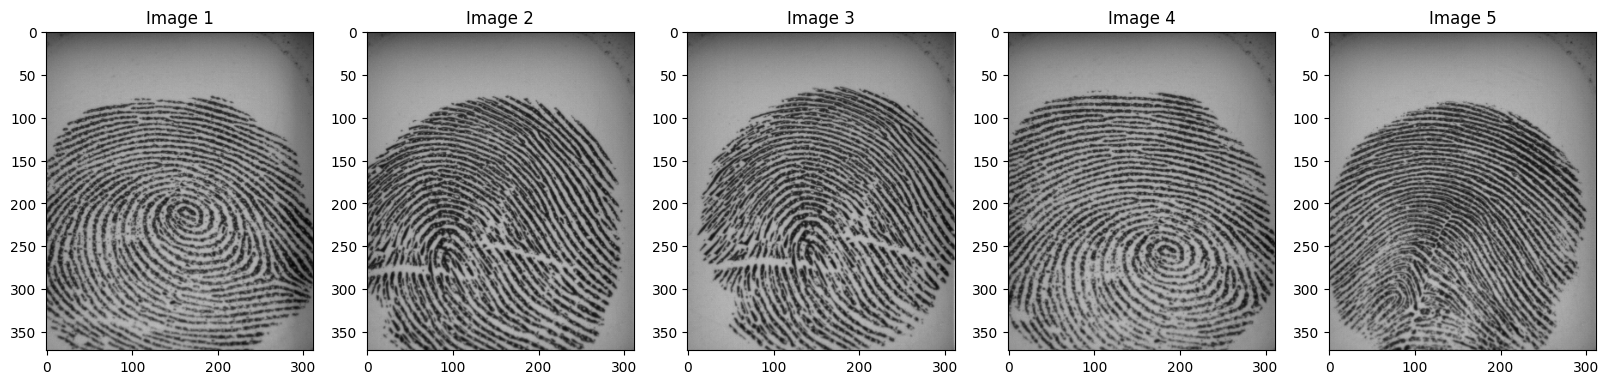

In [6]:
# Display Some of the testing images
fig = plt.figure(figsize=(20, 20))

image_num = 0
num_images = 5
# loop through the images
for image_idx in range(num_images):
    # Keep an incrementing count of each image
    a=fig.add_subplot(1, num_images, image_idx+1)
    # Add the image to the plot
    image_plot = plt.imshow(testing_dataset[image_idx])
    # Add a caption with the folder name
    a.set_title("Image " + str(image_idx+1))
        
# Show the plot
plt.show()

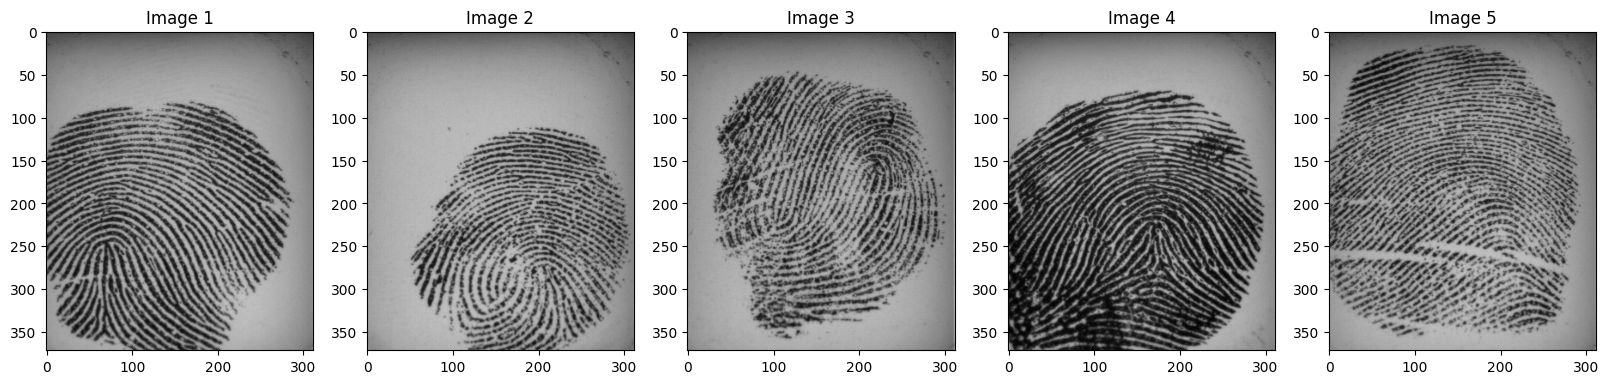

In [7]:
# Displaying Some of the Training Images
# Display Some of the testing images
fig = plt.figure(figsize=(20, 20))

image_num = 0
num_images = 5
# loop through the images
for image_idx in range(num_images):
    # Keep an incrementing count of each image
    a=fig.add_subplot(1, num_images, image_idx+1)
    # Add the image to the plot
    image_plot = plt.imshow(training_dataset[image_idx])
    # Add a caption with the folder name
    a.set_title("Image " + str(image_idx+1))
        
# Show the plot
plt.show()

In [8]:
# Resizing the Images
resized_training_dataset = []
for i in training_dataset:
   resized_training_dataset.append(resize(i, (128*4, 64*4))) 
resized_training_dataset[1].shape

(512, 256, 3)

In [9]:
# Resizing the Images
resized_testing_dataset = []
for i in testing_dataset:
   resized_testing_dataset.append(resize(i, (128*4, 64*4))) 
resized_testing_dataset[1].shape

(512, 256, 3)

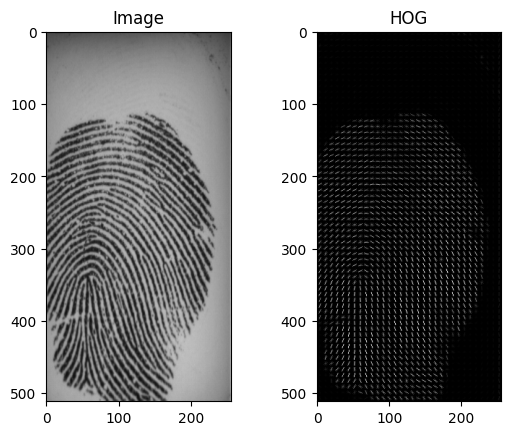

In [10]:
# Creating the HOG Features
fd, hog_image = hog(resized_training_dataset[0], orientations=9,
                    pixels_per_cell=(8, 8), cells_per_block=(2, 2),
                    visualize=True,channel_axis=-1)

plt.subplot(1, 2, 1); plt.imshow(resized_training_dataset[0], cmap="gray"); plt.title("Image")
plt.subplot(1, 2, 2); plt.imshow(hog_image, cmap="gray"); plt.title("HOG")
plt.show()

In [11]:
# Creating the HOG Features
def extract_hog_features(img):
    return hog(img, orientations=9, pixels_per_cell=(8, 8),
               cells_per_block=(2, 2),channel_axis=-1)


X_train = np.array([extract_hog_features(img) for img in resized_training_dataset])

In [12]:
X_train = np.array([extract_hog_features(img) for img in resized_training_dataset])
y_train = np.array(training_label)

X_test = np.array([extract_hog_features(img) for img in resized_testing_dataset])
y_test = np.array(testing_labels)

In [13]:
print(X_train.shape, X_test.shape)
print(y_train.shape, y_test.shape)


(407, 70308) (400, 70308)
(407,) (400,)


### Train and Evaluate

In [14]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import matthews_corrcoef
from sklearn.metrics import ConfusionMatrixDisplay

model = make_pipeline(StandardScaler(), SVC(kernel="rbf", C=1.0, gamma="scale"))
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
print(classification_report(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))

              precision    recall  f1-score   support

        live       0.98      0.79      0.87       200
       spoof       0.82      0.98      0.89       200

    accuracy                           0.88       400
   macro avg       0.90      0.88      0.88       400
weighted avg       0.90      0.88      0.88       400

[[157  43]
 [  4 196]]


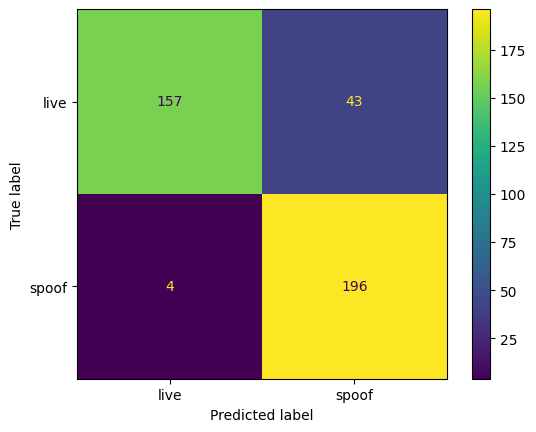

In [15]:

ConfusionMatrixDisplay.from_predictions(y_test, y_pred)
plt.show()

In [16]:
from sklearn.metrics import accuracy_score

print("Accuracy:", accuracy_score(y_test, y_pred))
print("MCC:", matthews_corrcoef(y_test, y_pred))

Accuracy: 0.8825
MCC: 0.7799729518106877


In [17]:
#lbp
def extract_lpb_features(img):
    radius = 3
    n_points = 8 * radius 
    method = 'uniform'
    lbp = local_binary_pattern(img, n_points, radius, method)

    n_bins = int(lbp.max() + 1)
    hist, _ = np.histogram(lbp.ravel(), bins=n_bins, range=(0, n_bins))
    hist = hist.astype("float")
    hist /= (hist.sum() + 1e-6)   # normalize to sum = 1 (avoid division by zero)
    return(hist)


In [18]:
X_train = np.array([extract_lpb_features(rgb2gray(img)) for img in resized_training_dataset])
y_train = np.array(training_label)

X_test = np.array([extract_lpb_features(rgb2gray(img)) for img in resized_testing_dataset])
y_test = np.array(testing_labels)

/opt/anaconda3/lib/python3.13/site-packages/skimage/feature/texture.py:385: UserWarning: Applying `local_binary_pattern` to floating-point images may give unexpected results when small numerical differences between adjacent pixels are present. It is recommended to use this function with images of integer dtype.
  warnings.warn(


### Training LBP features With SVM

In [19]:
model = make_pipeline(StandardScaler(), SVC(kernel="rbf", C=1.0, gamma="scale"))
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
print(classification_report(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))

              precision    recall  f1-score   support

        live       0.84      0.92      0.88       200
       spoof       0.91      0.82      0.86       200

    accuracy                           0.87       400
   macro avg       0.87      0.87      0.87       400
weighted avg       0.87      0.87      0.87       400

[[183  17]
 [ 35 165]]


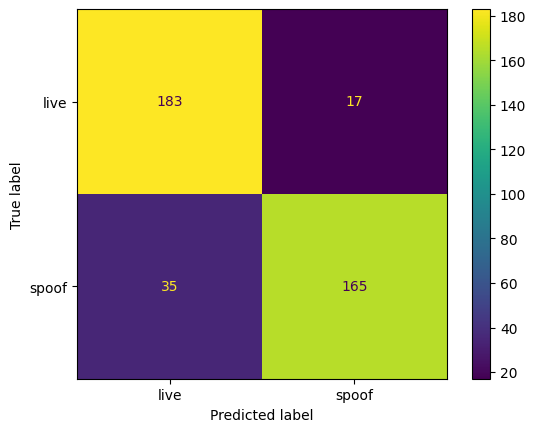

In [20]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred)
plt.show()

In [21]:
from sklearn.metrics import accuracy_score

print("Accuracy:", accuracy_score(y_test, y_pred))
print("MCC:", matthews_corrcoef(y_test, y_pred))

Accuracy: 0.87
MCC: 0.7430153305481519
